# Used Cars Dataset — Exploratory Data Analysis

Basic EDA covering shape, columns, data types, missing values, duplicates, and the target variable (`price`).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')

df = pd.read_csv('used_cars.csv')
df.head()

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,Ford,Utility Police Interceptor Base,2013,"51,000 mi.",E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,"$10,300"
1,Hyundai,Palisade SEL,2021,"34,742 mi.",Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,"$38,005"
2,Lexus,RX 350 RX 350,2022,"22,372 mi.",Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,"$54,598"
3,INFINITI,Q50 Hybrid Sport,2015,"88,900 mi.",Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,None reported,Yes,"$15,500"
4,Audi,Q3 45 S line Premium Plus,2021,"9,835 mi.",Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,"$34,999"


## 1. Shape

In [2]:
print(f'Rows: {df.shape[0]}')
print(f'Columns: {df.shape[1]}')

Rows: 4009
Columns: 12


## 2. Columns

In [3]:
df.columns.tolist()

['brand',
 'model',
 'model_year',
 'milage',
 'fuel_type',
 'engine',
 'transmission',
 'ext_col',
 'int_col',
 'accident',
 'clean_title',
 'price']

## 3. Data Types

In [4]:
df.dtypes

brand           object
model           object
model_year       int64
milage          object
fuel_type       object
engine          object
transmission    object
ext_col         object
int_col         object
accident        object
clean_title     object
price           object
dtype: object

In [5]:
# Detailed info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4009 entries, 0 to 4008
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   brand         4009 non-null   object
 1   model         4009 non-null   object
 2   model_year    4009 non-null   int64 
 3   milage        4009 non-null   object
 4   fuel_type     3839 non-null   object
 5   engine        4009 non-null   object
 6   transmission  4009 non-null   object
 7   ext_col       4009 non-null   object
 8   int_col       4009 non-null   object
 9   accident      3896 non-null   object
 10  clean_title   3413 non-null   object
 11  price         4009 non-null   object
dtypes: int64(1), object(11)
memory usage: 376.0+ KB


## 4. Missing Values

In [6]:
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({'missing_count': missing, 'missing_pct': missing_pct})
missing_df[missing_df['missing_count'] > 0].sort_values('missing_count', ascending=False)

,missing_count,missing_pct
clean_title,596,14.87
fuel_type,170,4.24
accident,113,2.82


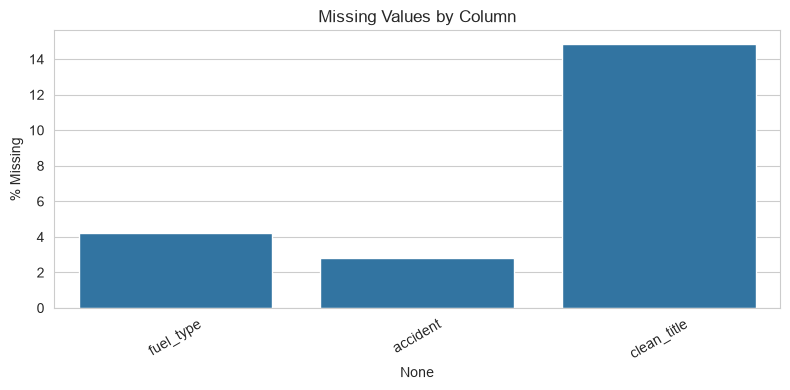

In [7]:
plt.figure(figsize=(8,4))
sns.barplot(x=missing_df[missing_df['missing_count']>0].index,
            y=missing_df[missing_df['missing_count']>0]['missing_pct'])
plt.ylabel('% Missing')
plt.title('Missing Values by Column')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 5. Duplicate Rows

In [8]:
print(f'Duplicate rows: {df.duplicated().sum()}')

Duplicate rows: 0


## 6. Unique Values per Column

In [9]:
df.nunique().sort_values(ascending=False)

milage          2818
model           1898
price           1569
engine          1146
ext_col          319
int_col          156
transmission      62
brand             57
model_year        34
fuel_type          7
accident           2
clean_title        1
dtype: int64

## 7. Cleaning `price` and `milage`

Both are stored as text (`"$10,300"`, `"51,000 mi."`) and need to be converted to numeric before analysis.

In [10]:
df['price_clean'] = (
    df['price'].str.replace(r'[\$,]', '', regex=True).astype(float)
)

df['milage_clean'] = (
    df['milage'].str.replace(r'[a-zA-Z.,\s]', '', regex=True).astype(float)
)

df[['price', 'price_clean', 'milage', 'milage_clean']].head()

,price,price_clean,milage,milage_clean
0,"$10,300",10300.0,"51,000 mi.",51000.0
1,"$38,005",38005.0,"34,742 mi.",34742.0
2,"$54,598",54598.0,"22,372 mi.",22372.0
3,"$15,500",15500.0,"88,900 mi.",88900.0
4,"$34,999",34999.0,"9,835 mi.",9835.0


## 8. Target Variable — `price`

In [11]:
df['price_clean'].describe()

count    4.009000e+03
mean     4.455319e+04
std      7.871064e+04
min      2.000000e+03
25%      1.720000e+04
50%      3.100000e+04
75%      4.999000e+04
max      2.954083e+06
Name: price_clean, dtype: float64

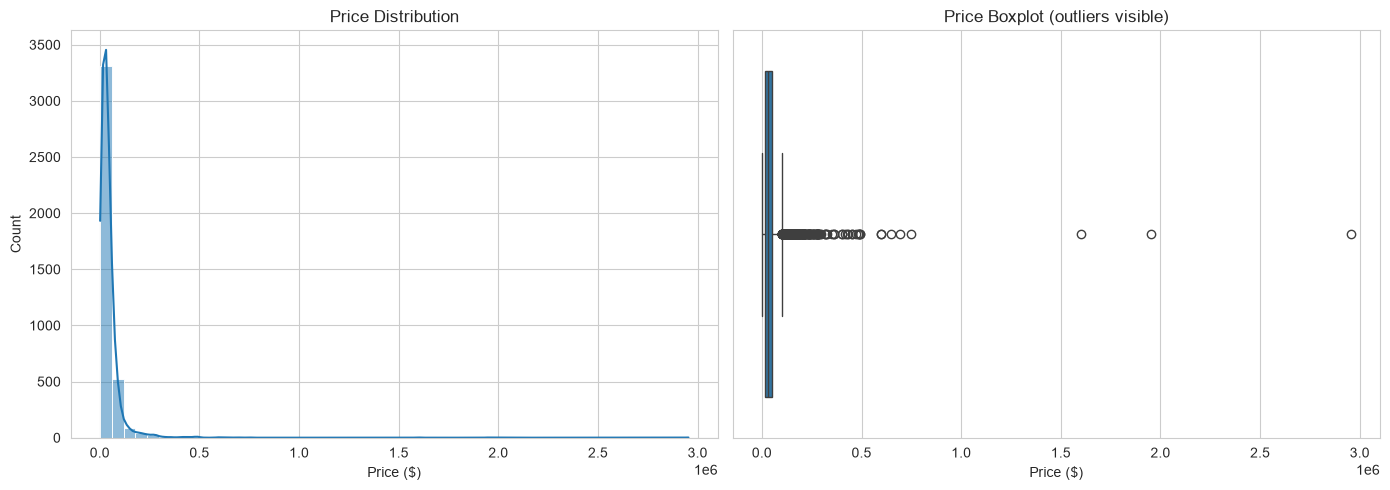

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14,5))

sns.histplot(df['price_clean'], bins=50, ax=axes[0], kde=True)
axes[0].set_title('Price Distribution')
axes[0].set_xlabel('Price ($)')

sns.boxplot(x=df['price_clean'], ax=axes[1])
axes[1].set_title('Price Boxplot (outliers visible)')
axes[1].set_xlabel('Price ($)')

plt.tight_layout()
plt.show()

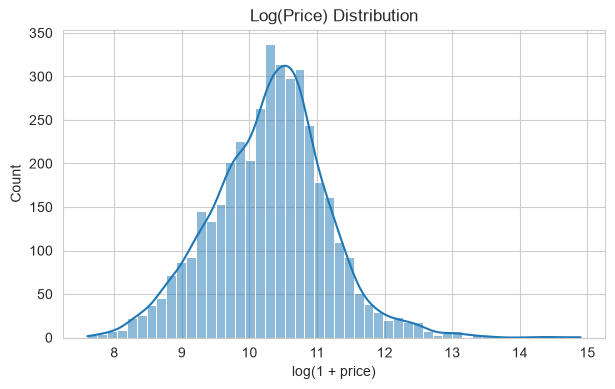

In [13]:
# Log-transformed view (price is heavily right-skewed)
plt.figure(figsize=(7,4))
sns.histplot(np.log1p(df['price_clean']), bins=50, kde=True)
plt.title('Log(Price) Distribution')
plt.xlabel('log(1 + price)')
plt.show()

In [14]:
# Top price outliers
df.nlargest(10, 'price_clean')[['brand','model','model_year','price_clean']]

,brand,model,model_year,price_clean
693,Maserati,Quattroporte Base,2005,2954083.0
229,Bugatti,Veyron 16.4 Grand Sport,2011,1950995.0
3046,Porsche,Carrera GT Base,2005,1599000.0
1356,Lamborghini,Aventador SVJ Base,2021,749950.0
624,Rolls-Royce,Cullinan,2022,695000.0
979,Lamborghini,Aventador SVJ Base,2019,649999.0
1615,Rolls-Royce,Phantom,2023,599995.0
1508,Rolls-Royce,Phantom,2018,599000.0
3655,Lamborghini,Aventador S Base,2018,491836.0
1061,Dodge,Viper GTC,2017,489995.0


## 9. Mileage

In [15]:
df['milage_clean'].describe()

count      4009.000000
mean      64717.551010
std       52296.599459
min         100.000000
25%       23044.000000
50%       52775.000000
75%       94100.000000
max      405000.000000
Name: milage_clean, dtype: float64

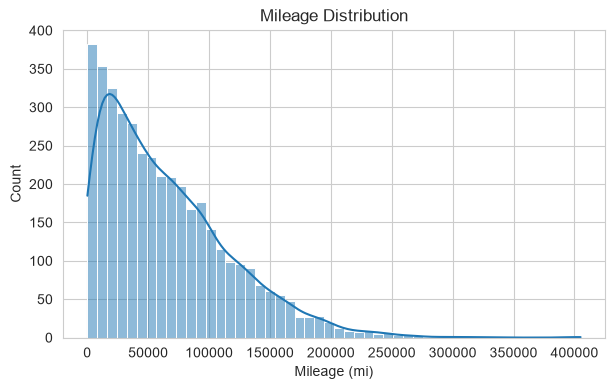

In [16]:
plt.figure(figsize=(7,4))
sns.histplot(df['milage_clean'], bins=50, kde=True)
plt.title('Mileage Distribution')
plt.xlabel('Mileage (mi)')
plt.show()

## 10. Model Year

In [17]:
df['model_year'].describe()

count    4009.000000
mean     2015.515590
std         6.104816
min      1974.000000
25%      2012.000000
50%      2017.000000
75%      2020.000000
max      2024.000000
Name: model_year, dtype: float64

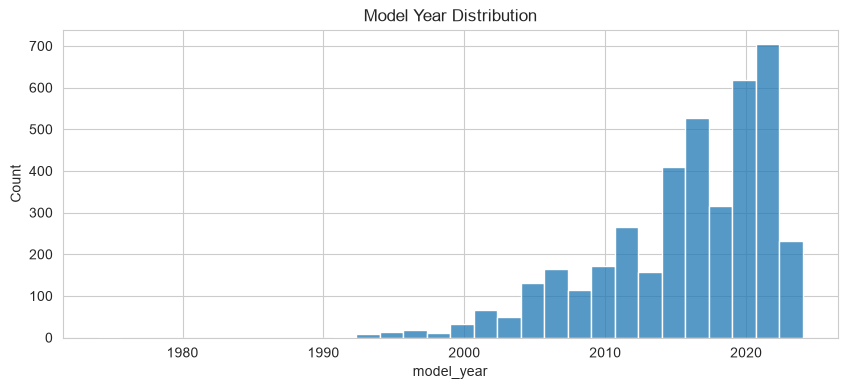

In [18]:
plt.figure(figsize=(10,4))
sns.histplot(df['model_year'], bins=30)
plt.title('Model Year Distribution')
plt.show()

## 11. Categorical Columns Overview

In [19]:
for col in ['fuel_type', 'accident', 'clean_title', 'transmission']:
    print(f"--- {col} ---")
    print(df[col].value_counts(dropna=False))
    print()

--- fuel_type ---
fuel_type
Gasoline          3309
Hybrid             194
NaN                170
E85 Flex Fuel      139
Diesel             116
–                   45
Plug-In Hybrid      34
not supported        2
Name: count, dtype: int64

--- accident ---
accident
None reported                             2910
At least 1 accident or damage reported     986
NaN                                        113
Name: count, dtype: int64

--- clean_title ---
clean_title
Yes    3413
NaN     596
Name: count, dtype: int64

--- transmission ---
transmission
A/T                                  1037
8-Speed A/T                           406
Transmission w/Dual Shift Mode        398
6-Speed A/T                           362
6-Speed M/T                           248
                                     ... 
10-Speed Automatic with Overdrive       1
9-Speed Automatic with Auto-Shift       1
SCHEDULED FOR OR IN PRODUCTION          1
6 Speed Mt                              1
8-Speed Manual                

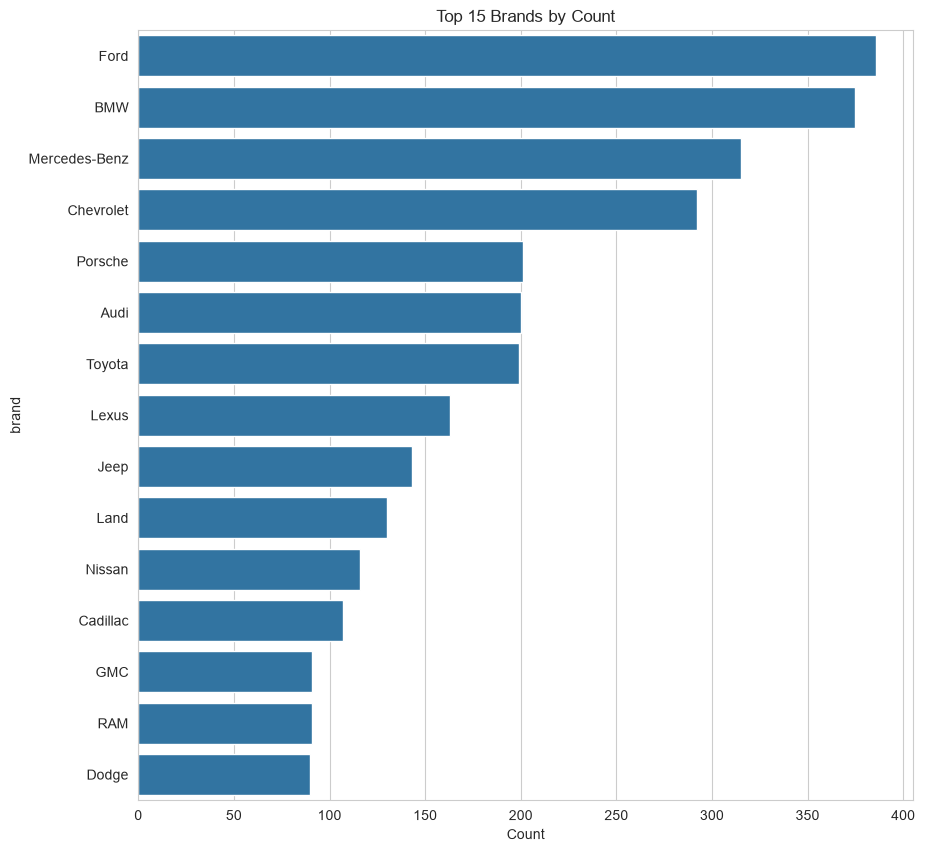

In [20]:
plt.figure(figsize=(10,10))
top_brands = df['brand'].value_counts().head(15)
sns.barplot(x=top_brands.values, y=top_brands.index)
plt.title('Top 15 Brands by Count')
plt.xlabel('Count')
plt.show()

## 12. Price vs. Key Features

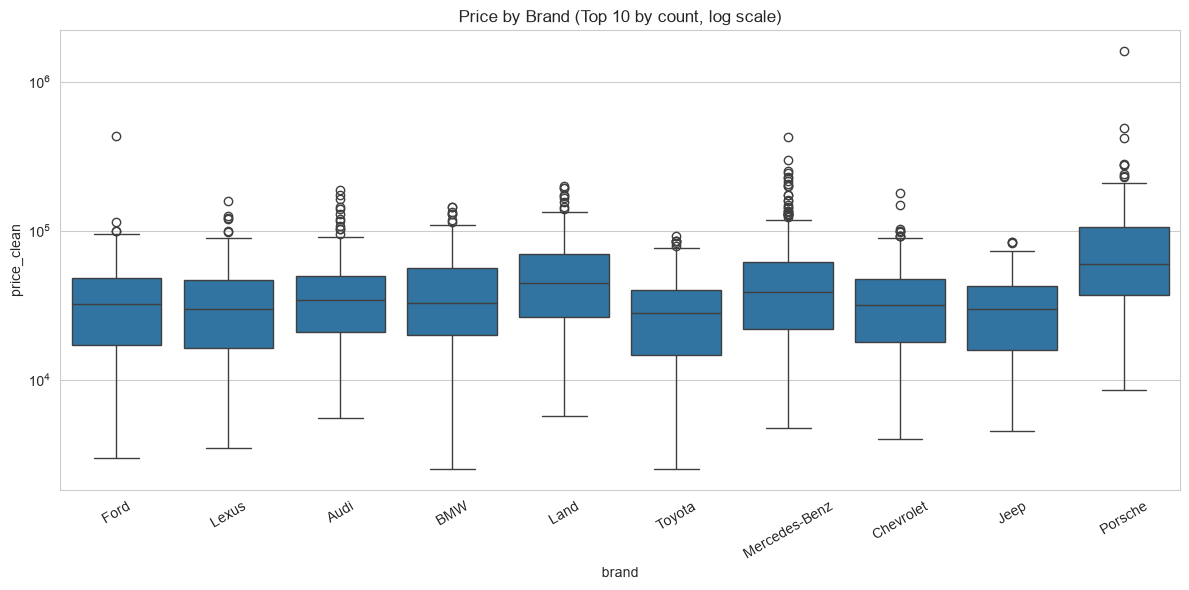

In [21]:
plt.figure(figsize=(12,6))
top_brand_names = df['brand'].value_counts().head(10).index
sns.boxplot(data=df[df['brand'].isin(top_brand_names)],
            x='brand', y='price_clean')
plt.yscale('log')
plt.title('Price by Brand (Top 10 by count, log scale)')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

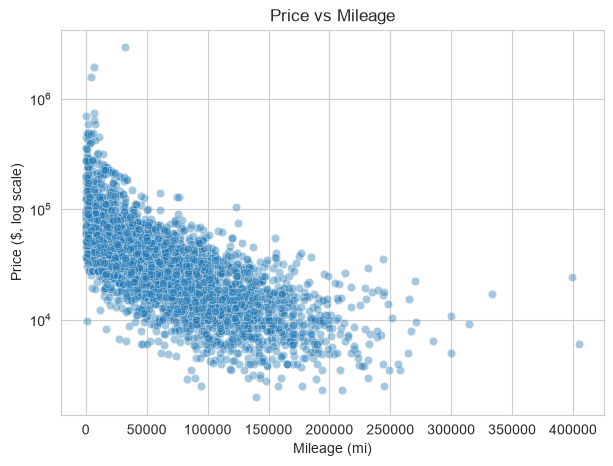

In [22]:
plt.figure(figsize=(7,5))
sns.scatterplot(data=df, x='milage_clean', y='price_clean', alpha=0.4)
plt.yscale('log')
plt.title('Price vs Mileage')
plt.xlabel('Mileage (mi)')
plt.ylabel('Price ($, log scale)')
plt.show()

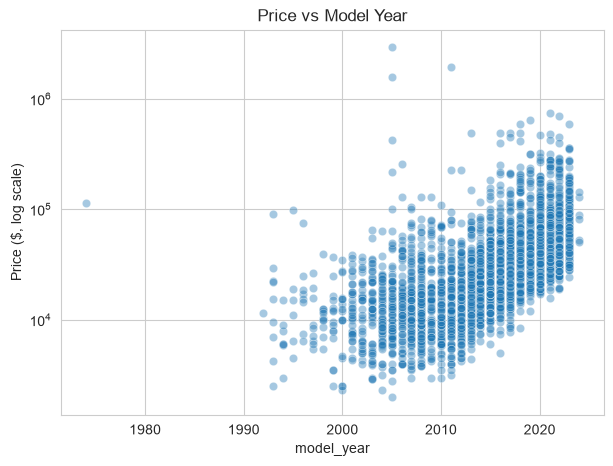

In [23]:
plt.figure(figsize=(7,5))
sns.scatterplot(data=df, x='model_year', y='price_clean', alpha=0.4)
plt.yscale('log')
plt.title('Price vs Model Year')
plt.ylabel('Price ($, log scale)')
plt.show()

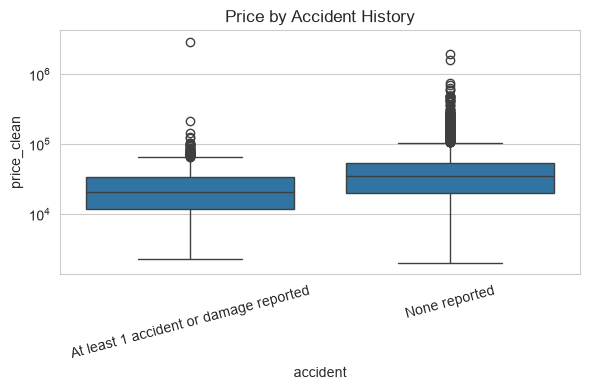

In [24]:
plt.figure(figsize=(6,4))
sns.boxplot(data=df, x='accident', y='price_clean')
plt.yscale('log')
plt.title('Price by Accident History')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## 13. Correlation (Numeric Features)

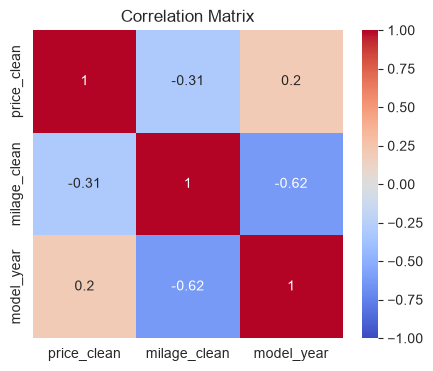

In [25]:
num_cols = ['price_clean', 'milage_clean', 'model_year']
corr = df[num_cols].corr()
plt.figure(figsize=(5,4))
sns.heatmap(corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Matrix')
plt.show()

## 14. Summary

- **4,009 rows, 12 columns**
- Target variable: **`price`** (cleaned to `price_clean`) — heavily right-skewed, mean ≈ $44.5K, median ≈ $31K, with extreme outliers up to ≈ $2.95M
- `milage` and `price` were stored as text and required cleaning to numeric
- Missing values present in `fuel_type` (170), `accident` (113), and `clean_title` (596 — effectively binary since only "Yes" appears)
- No duplicate rows
- Strong candidate predictors: `model_year`, `milage`, `brand`, `accident`, `fuel_type`